# Week 10 — Relationships & Modeling

**DATS 2102 · Data Visualization for Data Science**

**Datasets:** *Ames, Iowa* home sales (1,460 homes) for most of the session, and
*California housing* (20,640 block groups) for the section on large data.

Both are cached in `data/` so nothing here needs a network connection. If you
want to pull them fresh, the loaders are in the comments of the setup cell.

## Environment setup

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.api as sm

sns.set_theme(style="whitegrid")

# Cached locally. To refetch:
#   from sklearn.datasets import fetch_openml, fetch_california_housing
#   fetch_openml(data_id=42165, as_frame=True).frame        # Ames
#   fetch_california_housing(as_frame=True).frame           # California
df = pd.read_csv("data/ames.csv")
print(df.shape)
df.head()

(1460, 11)


,GrLivArea,SalePrice,YearBuilt,HouseStyle,OverallQual,TotalBsmtSF,GarageArea,LotArea,Neighborhood,CentralAir,YrSold
0,1710,208500,2003,2Story,7,856,548,8450,CollgCr,Y,2008
1,1262,181500,1976,1Story,6,1262,460,9600,Veenker,Y,2007
2,1786,223500,2001,2Story,7,920,608,11250,CollgCr,Y,2008
3,1717,140000,1915,2Story,7,756,642,9550,Crawfor,Y,2006
4,2198,250000,2000,2Story,8,1145,836,14260,NoRidge,Y,2008


### Variables we use

| Column | Meaning |
|---|---|
| `GrLivArea` | above-grade living area, square feet |
| `SalePrice` | sale price, dollars |
| `YearBuilt` | year the house was built |
| `HouseStyle` | `1Story`, `2Story`, and others |
| `OverallQual` | overall material and finish, 1–10 |

Our main question for the session: **how does living area relate to sale price,
and how well does a straight line describe that relationship?**

## Scatterplot

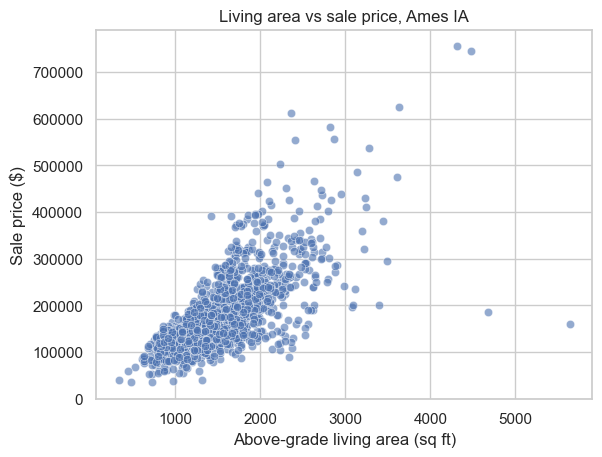

In [2]:
sns.scatterplot(data=df, x="GrLivArea", y="SalePrice", alpha=0.6)
plt.xlabel("Above-grade living area (sq ft)")
plt.ylabel("Sale price ($)")
plt.title("Living area vs sale price, Ames IA")
plt.show()

Positive, roughly linear, and with a handful of very large homes off to the
right. Note those already — they will matter when we look at residuals.

## Basic scatter + marginal histograms

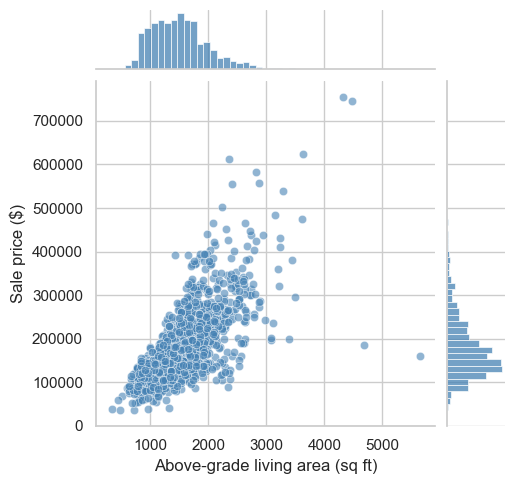

In [3]:
g = sns.jointplot(data=df, x="GrLivArea", y="SalePrice",
                  height=5, alpha=0.6, color="steelblue")
g.set_axis_labels("Above-grade living area (sq ft)", "Sale price ($)")
plt.show()

The margins tell you something the scatter alone does not: both variables are
right-skewed. Most homes are ordinary; a few are much bigger and much pricier.

## Scatterplot with regression line

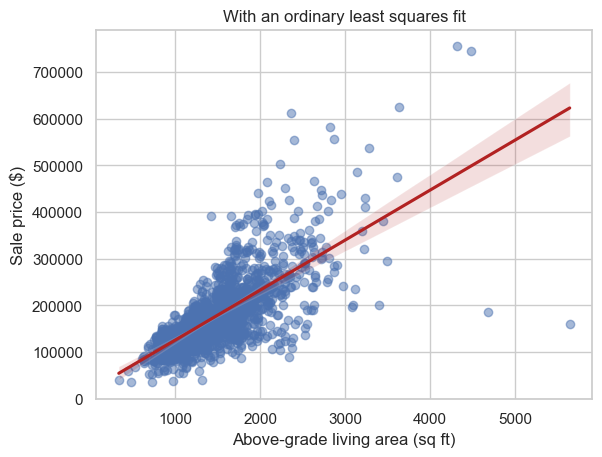

In [4]:
sns.regplot(data=df, x="GrLivArea", y="SalePrice",
            scatter_kws={"alpha": 0.5}, line_kws={"color": "firebrick"})
plt.xlabel("Above-grade living area (sq ft)")
plt.ylabel("Sale price ($)")
plt.title("With an ordinary least squares fit")
plt.show()

## Scatter with regression line and 95% confidence interval

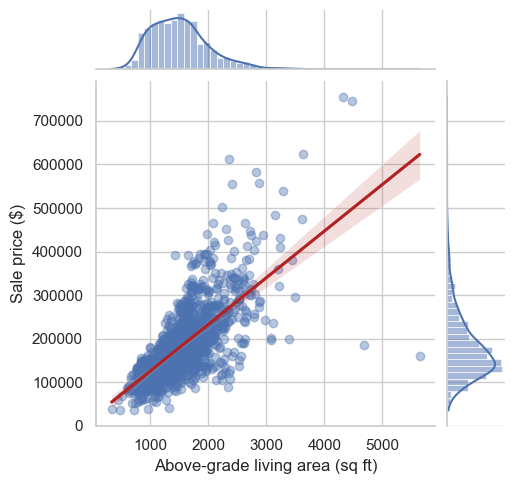

In [5]:
g = sns.jointplot(data=df, x="GrLivArea", y="SalePrice", kind="reg",
                  height=5, scatter_kws={"alpha": 0.4},
                  line_kws={"color": "firebrick"})
g.set_axis_labels("Above-grade living area (sq ft)", "Sale price ($)")
plt.show()

The shaded band is the confidence interval **for the fitted line**, not for
where an individual house will land. It is narrow in the middle, where the data
is dense, and flares at the edges. A common misreading is to treat it as a
prediction interval — it is much narrower than that.

## Multivariate: one line per group

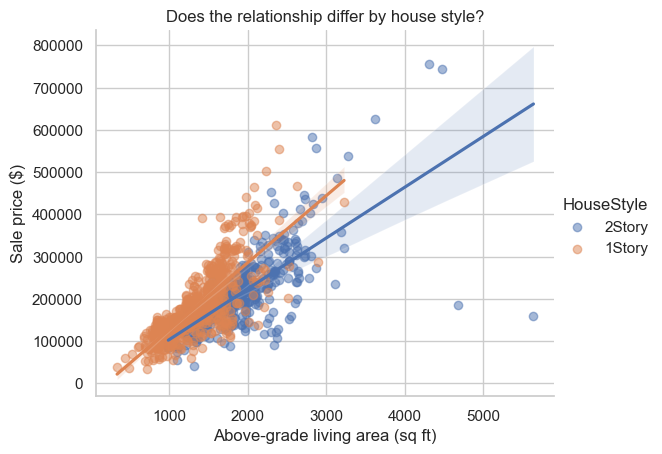

In [6]:
two = df[df["HouseStyle"].isin(["1Story", "2Story"])]
sns.lmplot(data=two, x="GrLivArea", y="SalePrice", hue="HouseStyle",
           height=4.5, aspect=1.3, scatter_kws={"alpha": 0.5})
plt.xlabel("Above-grade living area (sq ft)")
plt.ylabel("Sale price ($)")
plt.title("Does the relationship differ by house style?")
plt.show()

Two stories of the same square footage sell for *less* than one story of the
same square footage. The slopes differ too. A single pooled line would have
hidden both facts — this is the same lesson as Week 6: before you fit one line,
ask whether you are looking at one group or several.

## Correlation matrix heatmap

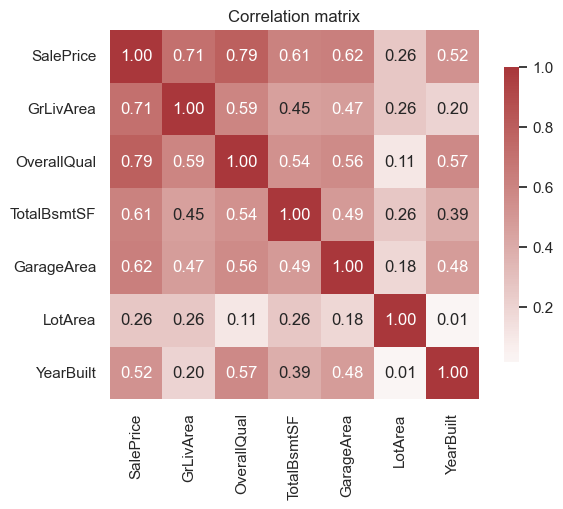

In [7]:
num = df[["SalePrice", "GrLivArea", "OverallQual", "TotalBsmtSF",
          "GarageArea", "LotArea", "YearBuilt"]]
corr = num.corr(numeric_only=True)

sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0,
            square=True, cbar_kws={"shrink": 0.8})
plt.title("Correlation matrix")
plt.show()

A diverging palette centered at zero, because the sign matters — this is Week 9
applied. A sequential palette here would make a correlation of -0.4 and +0.4
look like very different magnitudes.

## OLS: SalePrice ~ GrLivArea

In [8]:
X = sm.add_constant(df["GrLivArea"])
model = sm.OLS(df["SalePrice"], X).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:              SalePrice   R-squared:                       0.502
Model:                            OLS   Adj. R-squared:                  0.502
Method:                 Least Squares   F-statistic:                     1471.
Date:                Thu, 05 Nov 2026   Prob (F-statistic):          4.52e-223
Time:                        19:07:11   Log-Likelihood:                -18035.
No. Observations:                1460   AIC:                         3.607e+04
Df Residuals:                    1458   BIC:                         3.608e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       1.857e+04   4480.755      4.144      0.0

Read three things and ignore the rest for now:

- **coef on `GrLivArea`** — dollars per additional square foot
- **R-squared** — the share of variation in price this one variable accounts for
- **the confidence interval on the coefficient** — how precisely it is pinned down

## Residual diagnostics

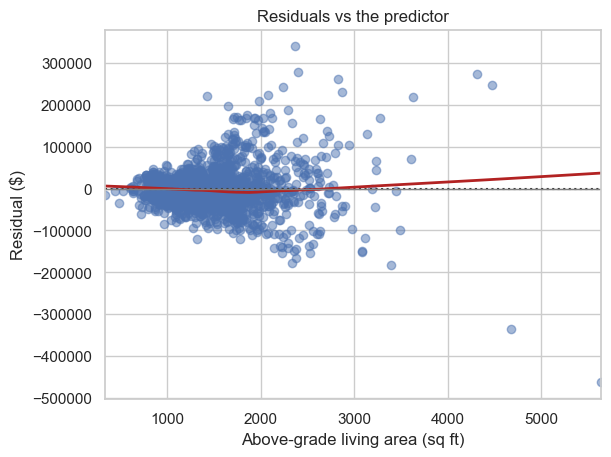

In [9]:
sns.residplot(data=df, x="GrLivArea", y="SalePrice", lowess=True,
              scatter_kws={"alpha": 0.5},
              line_kws={"color": "firebrick", "lw": 2})
plt.axhline(0, color="gray", lw=1)
plt.xlabel("Above-grade living area (sq ft)")
plt.ylabel("Residual ($)")
plt.title("Residuals vs the predictor")
plt.show()

**This is the most important plot in the notebook.** If the straight line were a
good description, this would be a shapeless band around zero. It is not: the
spread widens as homes get larger, and the smoother bends. Both are the model
telling you something the first scatterplot did not.

## Predicted vs actual

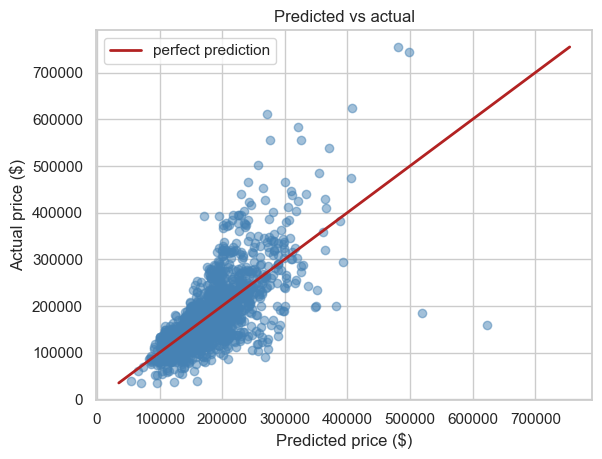

In [10]:
pred = model.predict(X)
lims = [df["SalePrice"].min(), df["SalePrice"].max()]

plt.scatter(pred, df["SalePrice"], alpha=0.5, color="steelblue")
plt.plot(lims, lims, color="firebrick", lw=2, label="perfect prediction")
plt.xlabel("Predicted price ($)")
plt.ylabel("Actual price ($)")
plt.title("Predicted vs actual")
plt.legend()
plt.show()

The reference line is `y = x`, not a fit. Points below it are homes the model
over-values; above it, under-values. The expensive homes sit almost entirely
above the line — a one-variable model systematically under-prices them.

## A nonlinear relationship

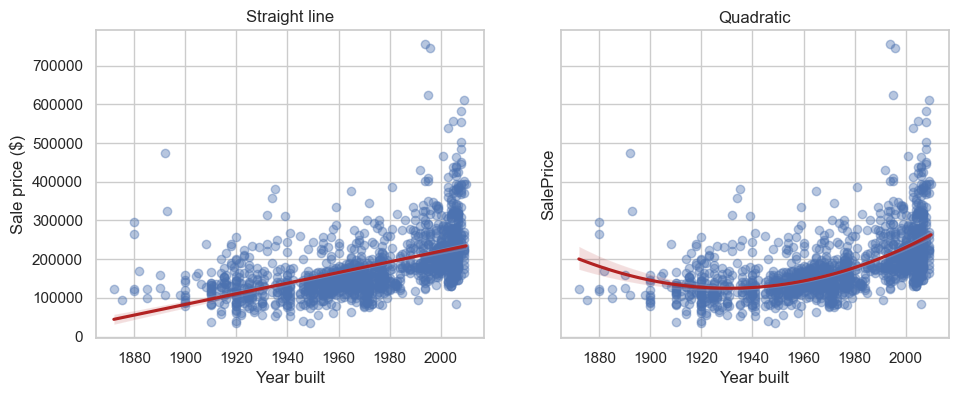

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)

sns.regplot(data=df, x="YearBuilt", y="SalePrice", ax=axes[0],
            scatter_kws={"alpha": 0.4}, line_kws={"color": "firebrick"})
axes[0].set_title("Straight line")

sns.regplot(data=df, x="YearBuilt", y="SalePrice", order=2, ax=axes[1],
            scatter_kws={"alpha": 0.4}, line_kws={"color": "firebrick"})
axes[1].set_title("Quadratic")

for a in axes:
    a.set_xlabel("Year built")
axes[0].set_ylabel("Sale price ($)")
plt.show()

Year built is not linear in price: very old homes and new homes are both worth
more than the mid-century stock. The straight line splits the difference and
describes neither. R-squared rises from about 0.27 to 0.35 with the quadratic
term — but you would have seen the problem from the picture first.

## Q–Q plot: are the residuals normal?

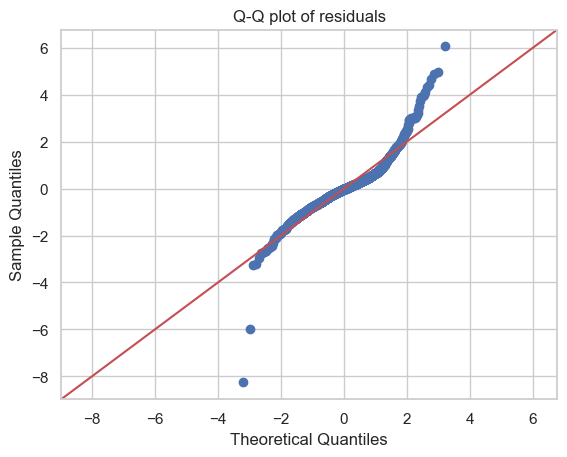

In [12]:
resid = model.resid
sm.qqplot(resid, line="45", fit=True)
plt.title("Q-Q plot of residuals")
plt.show()

## Residual histogram

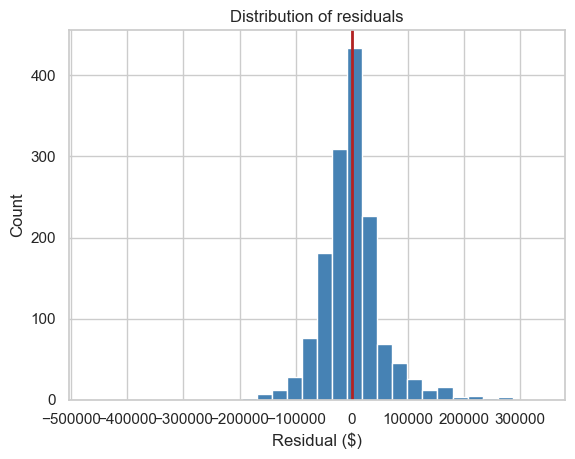

In [13]:
plt.hist(resid, bins=30, color="steelblue", edgecolor="white")
plt.axvline(0, color="firebrick", lw=2)
plt.xlabel("Residual ($)")
plt.ylabel("Count")
plt.title("Distribution of residuals")
plt.show()

Roughly centered and roughly symmetric, with a long right tail — the
under-priced expensive homes again, showing up in a third different plot.

## Heteroscedasticity: residuals vs fitted

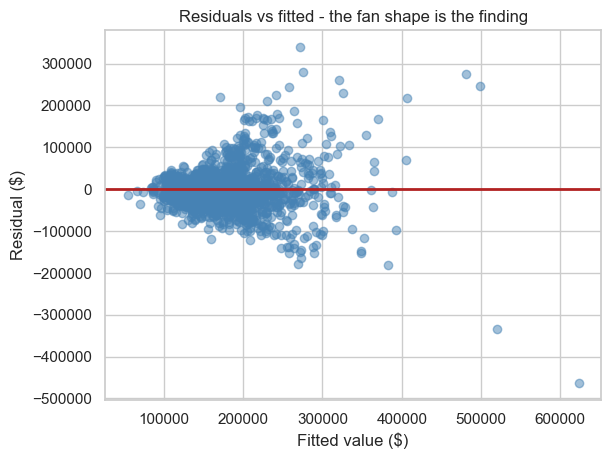

In [14]:
plt.scatter(model.fittedvalues, resid, alpha=0.5, color="steelblue")
plt.axhline(0, color="firebrick", lw=2)
plt.xlabel("Fitted value ($)")
plt.ylabel("Residual ($)")
plt.title("Residuals vs fitted - the fan shape is the finding")
plt.show()

The spread grows with the fitted value. That is *heteroscedasticity*: the model
is more wrong about expensive homes than cheap ones. The coefficient is still
usable; the confidence intervals are not trustworthy as reported.

## LOWESS guide line on residuals vs fitted

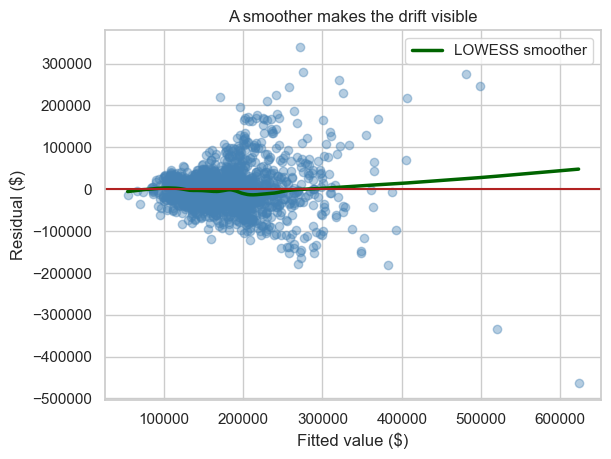

In [15]:
from statsmodels.nonparametric.smoothers_lowess import lowess

sm_line = lowess(resid, model.fittedvalues, frac=0.3, return_sorted=True)

plt.scatter(model.fittedvalues, resid, alpha=0.4, color="steelblue")
plt.plot(sm_line[:, 0], sm_line[:, 1], color="darkgreen", lw=2.5,
         label="LOWESS smoother")
plt.axhline(0, color="firebrick", lw=1.5)
plt.xlabel("Fitted value ($)")
plt.ylabel("Residual ($)")
plt.title("A smoother makes the drift visible")
plt.legend()
plt.show()

Your eye is bad at judging whether a cloud of points drifts. The smoother is
there to answer one question: **does the average residual stay at zero across
the range?** Here it does not.

## When n is large: overplotting

Everything above used 1,460 homes. Now switch to California — 20,640 block
groups — and watch the scatterplot stop working.

(20640, 9)


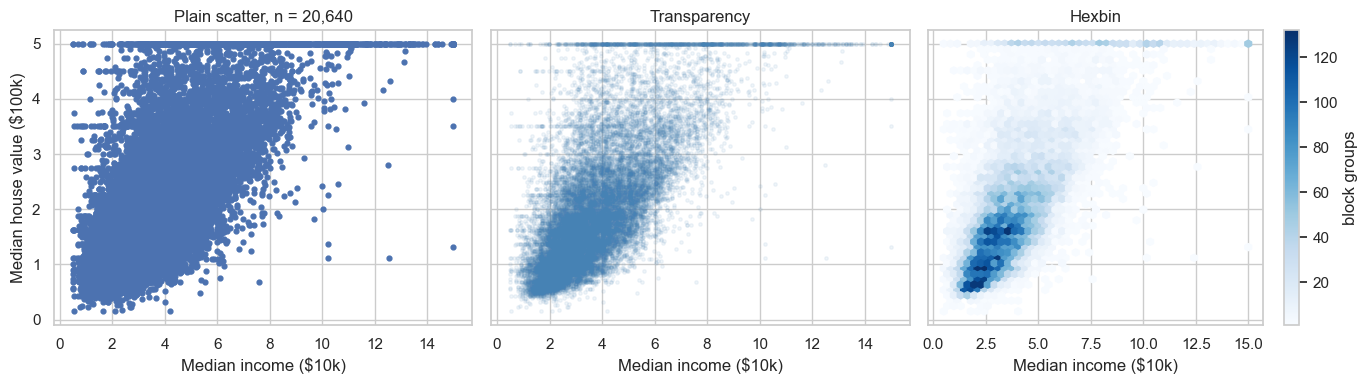

In [16]:
ca = pd.read_csv("data/california.csv")
print(ca.shape)

fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)

axes[0].scatter(ca["MedInc"], ca["MedHouseVal"], s=12)
axes[0].set_title(f"Plain scatter, n = {len(ca):,}")

axes[1].scatter(ca["MedInc"], ca["MedHouseVal"], s=6, alpha=0.08,
                color="steelblue")
axes[1].set_title("Transparency")

hb = axes[2].hexbin(ca["MedInc"], ca["MedHouseVal"], gridsize=45, cmap="Blues",
                    mincnt=1)
axes[2].set_title("Hexbin")
plt.colorbar(hb, ax=axes[2], label="block groups")

for a in axes:
    a.set_xlabel("Median income (\$10k)")
axes[0].set_ylabel("Median house value (\$100k)")
plt.tight_layout()
plt.show()

The left panel is a solid mass — it shows the *extent* of the data and nothing
about its *density*. The middle recovers some structure. The right one encodes
count directly and is the only panel where you can see where most block groups
actually are.

Also visible once the overplotting clears: a hard horizontal line at the top.
That is the value the dataset was **capped** at. Every block group above
\$500,000 was recorded as exactly \$500,001. A plain scatterplot hides that
completely, and any model fit without noticing it is fitting a ceiling.

## Reflection

1. Three different plots in this notebook pointed at the same problem — the
   expensive homes. Name them, and say what each one showed that the others did not.
2. The confidence band in the `jointplot` is narrower than most people expect.
   What exactly is it a confidence interval *for*?
3. In the California panel, what would you do about the capped values before
   fitting anything?